In [38]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Visualization settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


# Data Understanding

In [39]:
df = pd.read_csv('NexaBank_CSAT_NPS_Synthetic_5000.csv')

print("Dataset successfully loaded!")

Dataset successfully loaded!


In [40]:
df.head()

,Response_ID,Response_Date,Customer_ID,Customer_Segment,City,Channel,Service_Type,Issue_Category,CSAT_Score,NPS_Score,Feedback,Resolution_Status,First_Contact_Resolution,Response_Time_Min
0,RSP01996,2025-11-01,CUS00581,Mass Affluent,Bandung,Mobile App,Fund Transfer,Transaction Limit,3,10,Saya berharap waktu respons bisa lebih konsisten.,Resolved,False,3.3
1,RSP02316,2025-11-01,CUS01596,Everyday,Jakarta,Mobile App,Fund Transfer,Transfer Delay,4,9,Prosesnya mudah dan transaksi berjalan lancar.,Resolved,True,0.9
2,RSP01482,2025-11-01,CUS01898,Everyday,Surabaya,Mobile App,Account Access,OTP Issue,5,9,Prosesnya mudah dan transaksi berjalan lancar.,Resolved,True,1.7
3,RSP01488,2025-11-01,CUS00611,Micro Business,Bekasi,Mobile App,QRIS Payment,QRIS Failed,1,2,Pembayaran QRIS gagal dan status transaksi tid...,Unresolved,False,3.8
4,RSP02442,2025-11-01,CUS01253,Micro Business,Yogyakarta,Mobile App,Fund Transfer,Failed Transaction,2,3,Transaksi gagal dan saya membutuhkan penjelasa...,Unresolved,False,3.3


In [41]:
df.tail()

,Response_ID,Response_Date,Customer_ID,Customer_Segment,City,Channel,Service_Type,Issue_Category,CSAT_Score,NPS_Score,Feedback,Resolution_Status,First_Contact_Resolution,Response_Time_Min
4995,RSP00401,2026-10-31,CUS01560,Everyday,Bandung,Mobile App,Bill Payment,Payment Failed,2,6,Pembayaran gagal meskipun saldo sudah terpotong.,Unresolved,False,3.5
4996,RSP02218,2026-10-31,CUS01434,Student,Semarang,Chatbot,Fund Transfer,Failed Transaction,4,8,"Aplikasi mudah digunakan, sejauh ini pengalama...",Resolved,False,1.0
4997,RSP03649,2026-10-31,CUS00154,Everyday,Surabaya,Email,Fund Transfer,Transaction Limit,4,10,Informasi yang diberikan jelas dan membantu.,Resolved,True,236.9
4998,RSP04503,2026-10-31,CUS02034,Everyday,Bekasi,Chatbot,Fund Transfer,Failed Transaction,3,5,Saya berharap waktu respons bisa lebih konsisten.,Unresolved,False,2.0
4999,RSP03122,2026-10-31,CUS01642,Everyday,Surabaya,Mobile App,Account Access,Account Locked,4,6,Prosesnya mudah dan transaksi berjalan lancar.,Resolved,True,14.7


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Response_ID               5000 non-null   object 
 1   Response_Date             5000 non-null   object 
 2   Customer_ID               5000 non-null   object 
 3   Customer_Segment          5000 non-null   object 
 4   City                      5000 non-null   object 
 5   Channel                   5000 non-null   object 
 6   Service_Type              5000 non-null   object 
 7   Issue_Category            5000 non-null   object 
 8   CSAT_Score                5000 non-null   int64  
 9   NPS_Score                 5000 non-null   int64  
 10  Feedback                  5000 non-null   object 
 11  Resolution_Status         5000 non-null   object 
 12  First_Contact_Resolution  5000 non-null   bool   
 13  Response_Time_Min         5000 non-null   float64
dtypes: bool(

In [43]:
df.describe()

,CSAT_Score,NPS_Score,Response_Time_Min
count,5000.000000,5000.000000,5000.00000
mean,3.375200,7.459200,25.08888
std,1.141528,2.545198,70.39407
min,1.000000,0.000000,0.50000
25%,3.000000,6.000000,2.90000
50%,3.000000,8.000000,5.10000
75%,4.000000,10.000000,9.10000
max,5.000000,10.000000,1135.30000


In [44]:
df.dtypes

,0
Response_ID,object
Response_Date,object
Customer_ID,object
Customer_Segment,object
City,object
Channel,object
Service_Type,object
Issue_Category,object
CSAT_Score,int64
NPS_Score,int64


In [45]:
df['Response_Date'] = pd.to_datetime(
    df['Response_Date'],
    errors='coerce'
)

df['CSAT_Score'] = pd.to_numeric(
    df['CSAT_Score'],
    errors='coerce'
)

df['NPS_Score'] = pd.to_numeric(
    df['NPS_Score'],
    errors='coerce'
)

df['Response_Time_Min'] = pd.to_numeric(
    df['Response_Time_Min'],
    errors='coerce'
)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Response_ID               5000 non-null   object        
 1   Response_Date             5000 non-null   datetime64[ns]
 2   Customer_ID               5000 non-null   object        
 3   Customer_Segment          5000 non-null   object        
 4   City                      5000 non-null   object        
 5   Channel                   5000 non-null   object        
 6   Service_Type              5000 non-null   object        
 7   Issue_Category            5000 non-null   object        
 8   CSAT_Score                5000 non-null   int64         
 9   NPS_Score                 5000 non-null   int64         
 10  Feedback                  5000 non-null   object        
 11  Resolution_Status         5000 non-null   object        
 12  First_Contact_Resolu

In [46]:
Q1 = df['Response_Time_Min'].quantile(0.25)
Q3 = df['Response_Time_Min'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

outliers = df[
    (df['Response_Time_Min'] < lower_bound) |
    (df['Response_Time_Min'] > upper_bound)
]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Potential Outliers:", len(outliers))

Lower Bound: -6.399999999999999
Upper Bound: 18.4
Potential Outliers: 575


# Response Time Investigation

In [47]:
#Identifikasi pelanggan dengan waktu respons paling lama
slowest_responses = df.sort_values(
    by='Response_Time_Min',
    ascending=False
)

slowest_responses[
    [
        'Response_ID',
        'Channel',
        'Service_Type',
        'Issue_Category',
        'Response_Time_Min',
        'CSAT_Score',
        'NPS_Score',
        'Resolution_Status',
        'First_Contact_Resolution',
        'Feedback'
    ]
].head(10)

,Response_ID,Channel,Service_Type,Issue_Category,Response_Time_Min,CSAT_Score,NPS_Score,Resolution_Status,First_Contact_Resolution,Feedback
4301,RSP00610,Email,Card Services,Card Declined,1135.3,3,8,Resolved,True,"Layanan cukup baik, tetapi masih ada beberapa ..."
3584,RSP04386,Email,Bill Payment,General Inquiry,778.0,5,10,Resolved,True,Informasi yang diberikan jelas dan membantu.
344,RSP00659,Email,Fund Transfer,Transfer Delay,700.6,5,9,Resolved,False,"Aplikasi mudah digunakan, sejauh ini pengalama..."
2073,RSP01719,Email,Account Opening,Verification Delay,624.4,2,8,Resolved,False,Verifikasi akun berjalan terlalu lama.
1084,RSP02444,Email,Account Access,Login Problem,597.0,5,9,Resolved,False,Petugas membantu dengan jelas dan cepat.
3698,RSP03494,Email,Fund Transfer,General Inquiry,595.2,4,7,Resolved,True,Masalah saya terselesaikan dengan baik. Terima...
3107,RSP00702,Email,QRIS Payment,Refund Delay,577.6,1,6,Unresolved,False,Pengembalian dana membutuhkan waktu lebih lama...
1431,RSP04907,Email,Account Access,OTP Issue,562.6,4,9,Resolved,True,"Aplikasi mudah digunakan, sejauh ini pengalama..."
3259,RSP02481,Email,Bill Payment,Payment Failed,551.5,3,8,Resolved,False,Pengalaman saya biasa saja dan masih ada ruang...
2883,RSP01544,Email,Card Services,Card Declined,502.8,3,8,Resolved,True,Saya berharap waktu respons bisa lebih konsisten.


* 10 waktu respons terlama berasal
* Casenya kebanyakan Card Services, Bill Payment, Account Opening, Fund Ransfer dan terakhir QRIS Payment
* Menariknya NPS Score-nya rata-rata tinggi
* Hanya ada 1 sentiment negatif yaitu kendala QRIS Payment yang pengembalian dananya lama. Biasanya karena ada SLA
* Beberapa comment feedbacknya harap bisa menjadi lebih baik

In [48]:
channel_response = df.groupby('Channel').agg(
    total_responses=('Response_ID', 'count'),
    avg_response_time=('Response_Time_Min', 'mean'),
    median_response_time=('Response_Time_Min', 'median'),
    max_response_time=('Response_Time_Min', 'max'),
    avg_csat=('CSAT_Score', 'mean'),
    avg_nps=('NPS_Score', 'mean')
).round(2)

channel_response.sort_values(
    by='median_response_time',
    ascending=False
)

,total_responses,avg_response_time,median_response_time,max_response_time,avg_csat,avg_nps
Channel,,,,,,
Email,464,212.70,186.95,1135.3,2.91,6.85
Call Center,973,10.22,8.70,68.2,3.66,7.91
Mobile App,2445,5.78,5.00,30.8,3.51,7.70
Chatbot,1118,2.39,2.10,10.3,3.03,6.79


* Respons terlama ada di channel Email dengan CSAT 2.92 dan NPS 6.85 cenderung rendah
* Tapi channel Chatbot dengan respons tercepat juga termasuk rendah yaitu CSAT 3.03 dan NPS 6.79
* Yang paling memuaskan Channel Call Center dengan CSAT 3.66 dan NPS 7.91

In [49]:
issue_response = df.groupby('Issue_Category').agg(
    total_responses=('Response_ID', 'count'),
    avg_response_time=('Response_Time_Min', 'mean'),
    median_response_time=('Response_Time_Min', 'median'),
    max_response_time=('Response_Time_Min', 'max'),
    avg_csat=('CSAT_Score', 'mean'),
    avg_nps=('NPS_Score', 'mean')
).round(2)

issue_response.sort_values(
    by='median_response_time',
    ascending=False
)

,total_responses,avg_response_time,median_response_time,max_response_time,avg_csat,avg_nps
Issue_Category,,,,,,
Application Status,117,33.21,5.60,352.1,3.74,8.04
OTP Issue,252,30.28,5.55,562.6,3.61,7.73
Account Locked,174,34.08,5.50,491.2,3.37,7.44
Login Problem,301,34.22,5.50,597.0,3.76,8.03
Card Blocked,137,20.37,5.50,361.4,3.73,8.23
Refund Delay,341,23.14,5.50,577.6,3.14,7.20
Transaction Limit,271,26.24,5.30,457.9,3.85,8.12
Transfer Delay,424,24.48,5.20,700.6,3.11,7.11
Verification Delay,175,26.09,5.20,624.4,2.97,6.67


* Issue category yang memiliki median response time tertinggi adalah Application Status, namun CSAT dan NPS-nya lumayan. Bisa disimpulkan kendalanya terselesaikan dengan baik
* Uniknya waktu respons tercepat CSAT sama NPS-nya ga lebih tinggi dari response time yang tinggi

In [50]:
service_response = df.groupby('Service_Type').agg(
    total_responses=('Response_ID', 'count'),
    avg_response_time=('Response_Time_Min', 'mean'),
    median_response_time=('Response_Time_Min', 'median'),
    avg_csat=('CSAT_Score', 'mean')
).round(2)

service_response.sort_values(
    by='median_response_time',
    ascending=False
)

,total_responses,avg_response_time,median_response_time,avg_csat
Service_Type,,,,
Account Access,876,31.29,5.4,3.62
Account Opening,496,24.67,5.1,3.32
Bill Payment,775,23.82,5.1,3.12
Fund Transfer,1261,23.46,5.1,3.39
QRIS Payment,882,23.27,5.1,3.18
Card Services,710,24.27,5.0,3.59


In [51]:
df['Response_Time_Group'] = np.where(
    df['Response_Time_Min'] > upper_bound,
    'Long Response Time',
    'Normal Response Time'
)

In [52]:
response_comparison = df.groupby(
    'Response_Time_Group'
).agg(
    total_responses=('Response_ID', 'count'),
    avg_csat=('CSAT_Score', 'mean'),
    avg_nps=('NPS_Score', 'mean'),
    unresolved_rate=(
        'Resolution_Status',
        lambda x: (x == 'Unresolved').mean() * 100
    ),
    fcr_rate=(
        'First_Contact_Resolution',
        'mean'
    )
).round(2)

response_comparison

,total_responses,avg_csat,avg_nps,unresolved_rate,fcr_rate
Response_Time_Group,,,,,
Long Response Time,575,3.00,7.02,23.83,0.50
Normal Response Time,4425,3.42,7.52,24.23,0.52


* Long response terlihat CSAT dan NPS-nya lebih rendah dibanding normal response, namun tidak terpaut jauh

In [53]:
fastest_responses = df.sort_values(
    by='Response_Time_Min',
    ascending=True
)

fastest_responses[
    [
        'Channel',
        'Service_Type',
        'Issue_Category',
        'Response_Time_Min',
        'CSAT_Score',
        'NPS_Score',
        'Resolution_Status',
        'First_Contact_Resolution'
    ]
].head(10)

,Channel,Service_Type,Issue_Category,Response_Time_Min,CSAT_Score,NPS_Score,Resolution_Status,First_Contact_Resolution
789,Chatbot,Account Opening,Verification Delay,0.5,2,5,Resolved,True
3157,Chatbot,Card Services,Card Declined,0.5,3,7,Resolved,True
1113,Chatbot,Card Services,Card Delivery,0.5,4,8,Resolved,True
3956,Chatbot,Account Opening,General Inquiry,0.5,4,9,Resolved,True
372,Chatbot,Account Opening,Application Status,0.5,4,8,Resolved,True
2675,Chatbot,Account Opening,Verification Delay,0.5,4,9,Resolved,False
1756,Mobile App,QRIS Payment,Payment Not Reflected,0.5,3,7,Resolved,False
1863,Chatbot,Account Access,Account Locked,0.5,3,5,Resolved,True
1958,Chatbot,Account Opening,Verification Delay,0.5,3,7,Resolved,True
1871,Chatbot,Card Services,Card Delivery,0.5,1,4,Unresolved,False


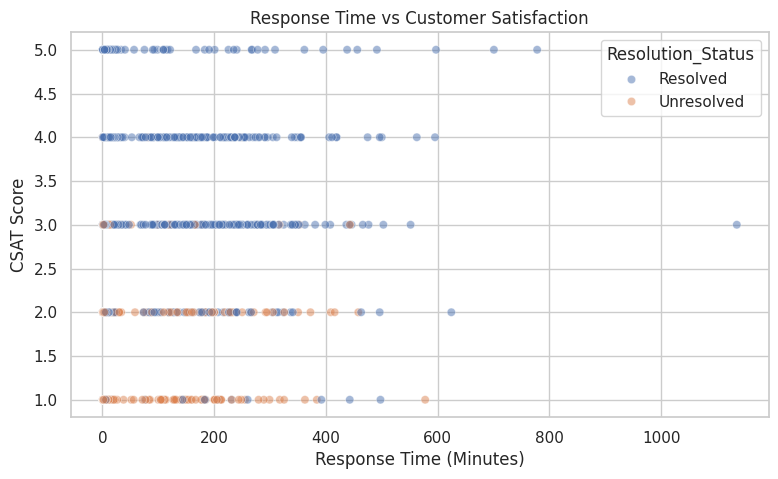

In [54]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='Response_Time_Min',
    y='CSAT_Score',
    hue='Resolution_Status',
    alpha=0.5
)

plt.title('Response Time vs Customer Satisfaction')
plt.xlabel('Response Time (Minutes)')
plt.ylabel('CSAT Score')
plt.show()

In [55]:
df[
    ['Response_Time_Min', 'CSAT_Score', 'NPS_Score']
].corr().round(3)

,Response_Time_Min,CSAT_Score,NPS_Score
Response_Time_Min,1.000,-0.090,-0.039
CSAT_Score,-0.090,1.000,0.753
NPS_Score,-0.039,0.753,1.000


# CSAT & NPS Distribution Analysis

In [56]:
#CSAT Score Distribution
df['CSAT_Score'].value_counts().sort_index()

,count
CSAT_Score,
1,354
2,759
3,1394
4,1643
5,850


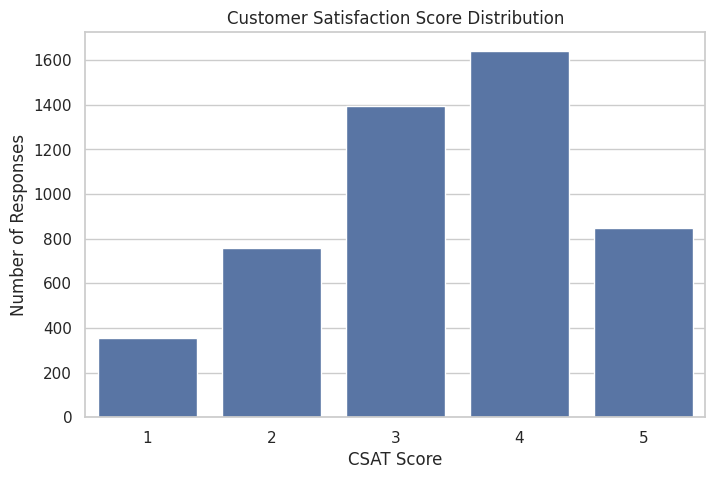

In [57]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='CSAT_Score'
)

plt.title('Customer Satisfaction Score Distribution')
plt.xlabel('CSAT Score')
plt.ylabel('Number of Responses')
plt.show()

In [58]:
#NPS Category Distribution
def categorize_nps(score):
    if score <= 6:
        return 'Detractors'
    elif score <= 8:
        return 'Passives'
    else:
        return 'Promoters'

df['NPS_Category'] = df['NPS_Score'].apply(categorize_nps)

df['NPS_Category'].value_counts()

,count
NPS_Category,
Promoters,2230
Detractors,1568
Passives,1202


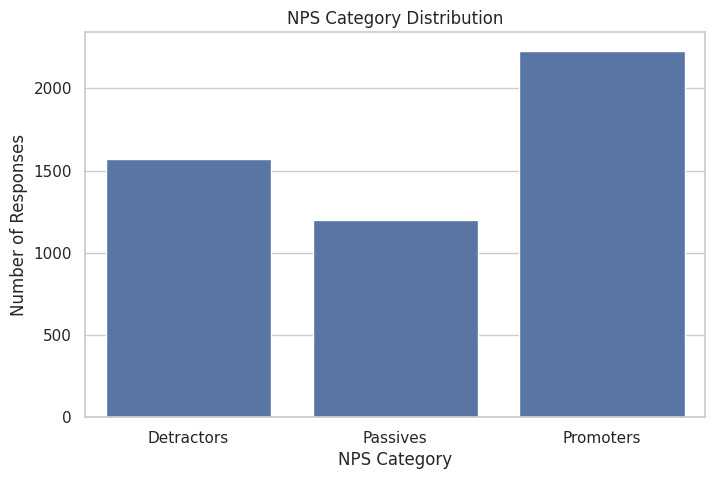

In [59]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='NPS_Category',
    order=['Detractors', 'Passives', 'Promoters']
)

plt.title('NPS Category Distribution')
plt.xlabel('NPS Category')
plt.ylabel('Number of Responses')
plt.show()

# Deep Analysis

* Channel & Service Analysis — channel dan layanan mana yang memiliki performa CX terbaik atau terburuk?

* Monthly Trend Analysis — apakah CSAT dan NPS membaik atau memburuk dari bulan ke bulan?

* Correlation Analysis — variabel apa yang memiliki hubungan dengan kepuasan pelanggan?

## Channel & Service Analysis

In [60]:
channel_analysis = df.groupby('Channel').agg(
    total_responses=('Response_ID', 'count'),
    avg_csat=('CSAT_Score', 'mean'),
    csat_satisfied=('CSAT_Score', lambda x: (x >= 4).mean() * 100),
    avg_nps_score=('NPS_Score', 'mean'),
    avg_response_time=('Response_Time_Min', 'mean'),
    median_response_time=('Response_Time_Min', 'median'),
    unresolved_rate=('Resolution_Status',
                     lambda x: (x == 'Unresolved').mean() * 100),
    fcr_rate=('First_Contact_Resolution', 'mean')
).round(2)

channel_analysis.sort_values(
    by='avg_csat',
    ascending=False
)

,total_responses,avg_csat,csat_satisfied,avg_nps_score,avg_response_time,median_response_time,unresolved_rate,fcr_rate
Channel,,,,,,,,
Call Center,973,3.66,60.43,7.91,10.22,8.70,15.31,0.63
Mobile App,2445,3.51,55.13,7.70,5.78,5.00,22.25,0.52
Chatbot,1118,3.03,36.49,6.79,2.39,2.10,35.96,0.44
Email,464,2.91,32.11,6.85,212.70,186.95,24.57,0.48


In [61]:
channel_analysis['fcr_rate'] = (
    channel_analysis['fcr_rate'] * 100
).round(2)

channel_analysis

,total_responses,avg_csat,csat_satisfied,avg_nps_score,avg_response_time,median_response_time,unresolved_rate,fcr_rate
Channel,,,,,,,,
Call Center,973,3.66,60.43,7.91,10.22,8.70,15.31,63.0
Chatbot,1118,3.03,36.49,6.79,2.39,2.10,35.96,44.0
Email,464,2.91,32.11,6.85,212.70,186.95,24.57,48.0
Mobile App,2445,3.51,55.13,7.70,5.78,5.00,22.25,52.0


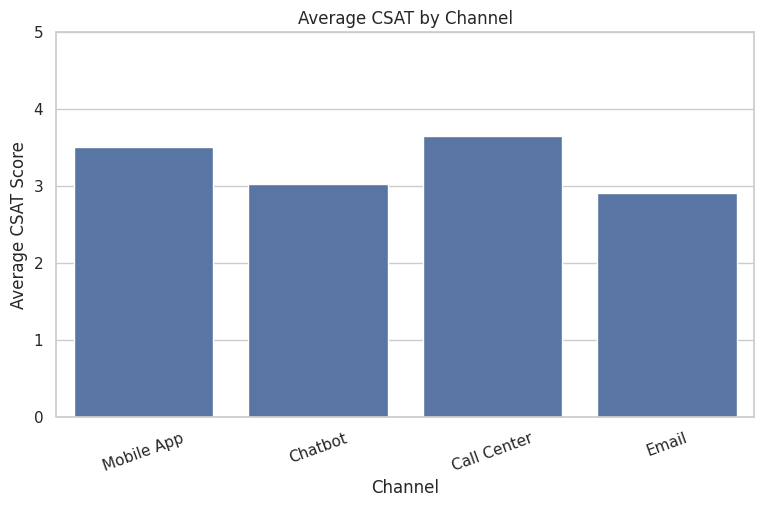

In [62]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='Channel',
    y='CSAT_Score',
    errorbar=None
)

plt.title('Average CSAT by Channel')
plt.xlabel('Channel')
plt.ylabel('Average CSAT Score')
plt.ylim(0, 5)
plt.xticks(rotation=20)
plt.show()

## Service Perfomance

In [63]:
service_analysis = df.groupby('Service_Type').agg(
    total_responses=('Response_ID', 'count'),
    avg_csat=('CSAT_Score', 'mean'),
    avg_nps=('NPS_Score', 'mean'),
    avg_response_time=('Response_Time_Min', 'mean'),
    unresolved_rate=('Resolution_Status',
                     lambda x: (x == 'Unresolved').mean() * 100),
    fcr_rate=('First_Contact_Resolution',
              lambda x: x.mean() * 100)
).round(2)

service_analysis.sort_values(
    by='avg_csat',
    ascending=False
)

,total_responses,avg_csat,avg_nps,avg_response_time,unresolved_rate,fcr_rate
Service_Type,,,,,,
Account Access,876,3.62,7.84,31.29,17.92,57.53
Card Services,710,3.59,7.78,24.27,18.73,57.04
Fund Transfer,1261,3.39,7.46,23.46,25.54,50.44
Account Opening,496,3.32,7.38,24.67,22.98,52.62
QRIS Payment,882,3.18,7.24,23.27,27.55,49.09
Bill Payment,775,3.12,7.03,23.82,30.97,45.42


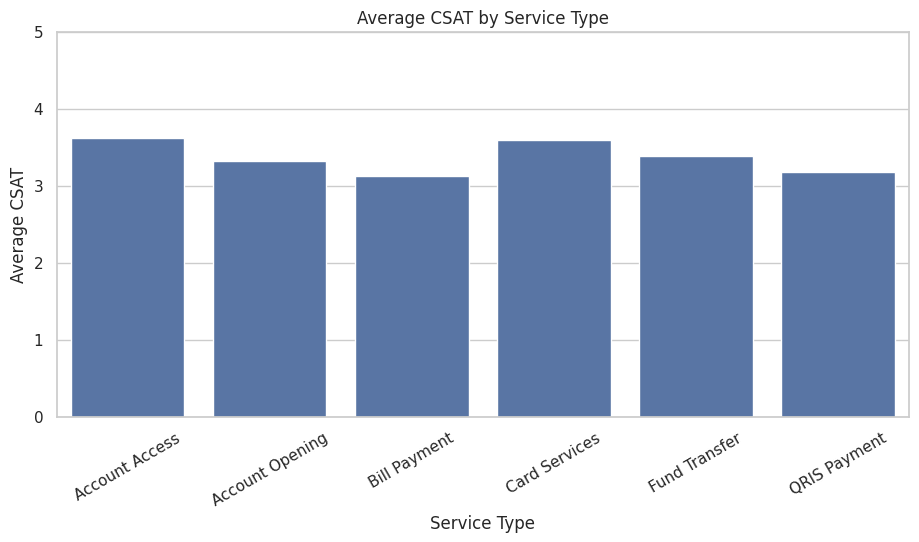

In [64]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=service_analysis.reset_index(),
    x='Service_Type',
    y='avg_csat',
    errorbar=None
)

plt.title('Average CSAT by Service Type')
plt.xlabel('Service Type')
plt.ylabel('Average CSAT')
plt.xticks(rotation=30)
plt.ylim(0, 5)
plt.show()

In [65]:
channel_service = df.pivot_table(
    index='Service_Type',
    columns='Channel',
    values='CSAT_Score',
    aggfunc='mean'
).round(2)

channel_service

Channel,Call Center,Chatbot,Email,Mobile App
Service_Type,,,,
Account Access,4.04,3.24,3.21,3.75
Account Opening,3.46,3.09,2.80,3.47
Bill Payment,3.38,2.66,2.63,3.31
Card Services,3.97,3.32,2.96,3.67
Fund Transfer,3.62,3.05,2.94,3.53
QRIS Payment,3.48,2.84,2.73,3.31


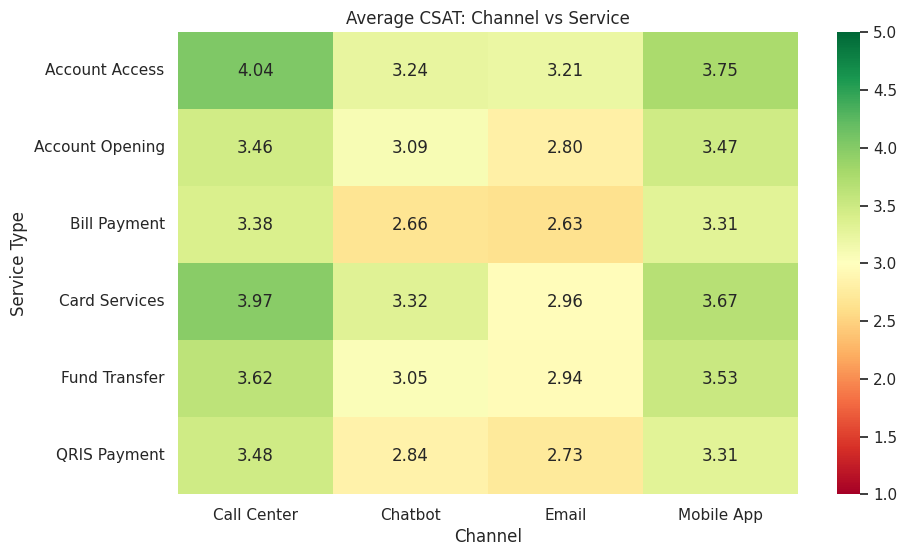

In [66]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    channel_service,
    annot=True,
    cmap='RdYlGn',
    vmin=1,
    vmax=5,
    fmt='.2f'
)

plt.title('Average CSAT: Channel vs Service')
plt.xlabel('Channel')
plt.ylabel('Service Type')
plt.show()

## Monthly Trend Analysis

In [67]:
df['Month'] = (
    df['Response_Date']
    .dt.to_period('M')
    .astype(str)
)

In [68]:
monthly_analysis = df.groupby('Month').agg(
    total_responses=('Response_ID', 'count'),

    csat_percentage=(
        'CSAT_Score',
        lambda x: (x >= 4).mean() * 100
    ),

    promoters_percentage=(
        'NPS_Score',
        lambda x: (x >= 9).mean() * 100
    ),

    detractors_percentage=(
        'NPS_Score',
        lambda x: (x <= 6).mean() * 100
    ),

    avg_response_time=('Response_Time_Min', 'mean'),

    unresolved_rate=(
        'Resolution_Status',
        lambda x: (x == 'Unresolved').mean() * 100
    )
)

monthly_analysis['nps'] = (
    monthly_analysis['promoters_percentage']
    - monthly_analysis['detractors_percentage']
).round(2)

monthly_analysis = monthly_analysis.round(2)

monthly_analysis

,total_responses,csat_percentage,promoters_percentage,detractors_percentage,avg_response_time,unresolved_rate,nps
Month,,,,,,,
2025-11,384,47.66,45.83,29.69,24.45,21.88,16.15
2025-12,468,48.50,41.45,33.97,22.48,28.42,7.48
2026-01,420,54.52,51.19,26.90,22.39,19.05,24.29
2026-02,395,50.89,46.84,28.10,32.63,23.29,18.73
2026-03,409,51.34,42.05,31.78,27.27,27.63,10.27
2026-04,435,47.13,42.07,34.71,23.97,26.44,7.36
2026-05,427,47.78,44.50,30.68,22.12,24.36,13.82
2026-06,387,50.65,44.44,29.97,27.81,22.22,14.47
2026-07,398,51.76,44.47,30.40,28.12,24.12,14.07


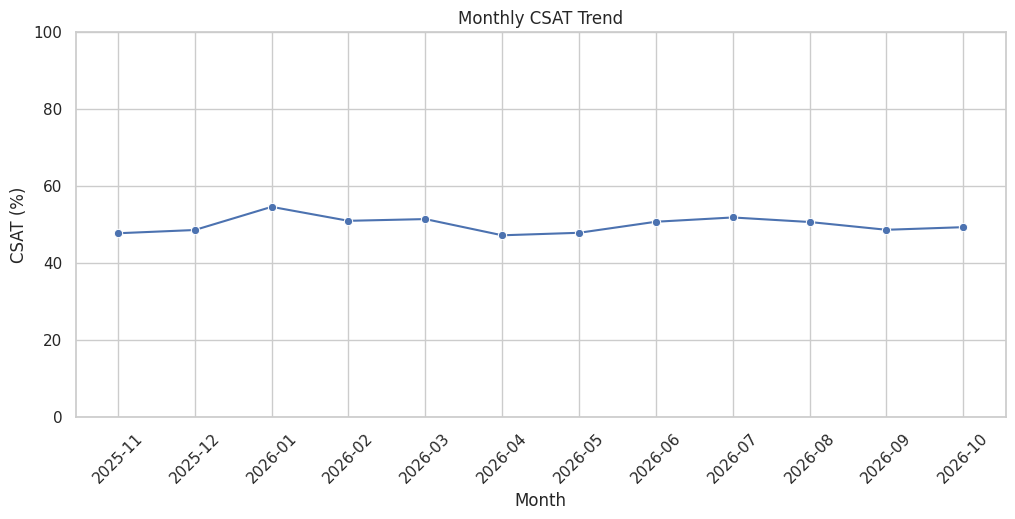

In [69]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_analysis.reset_index(),
    x='Month',
    y='csat_percentage',
    marker='o'
)

plt.title('Monthly CSAT Trend')
plt.xlabel('Month')
plt.ylabel('CSAT (%)')
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.show()

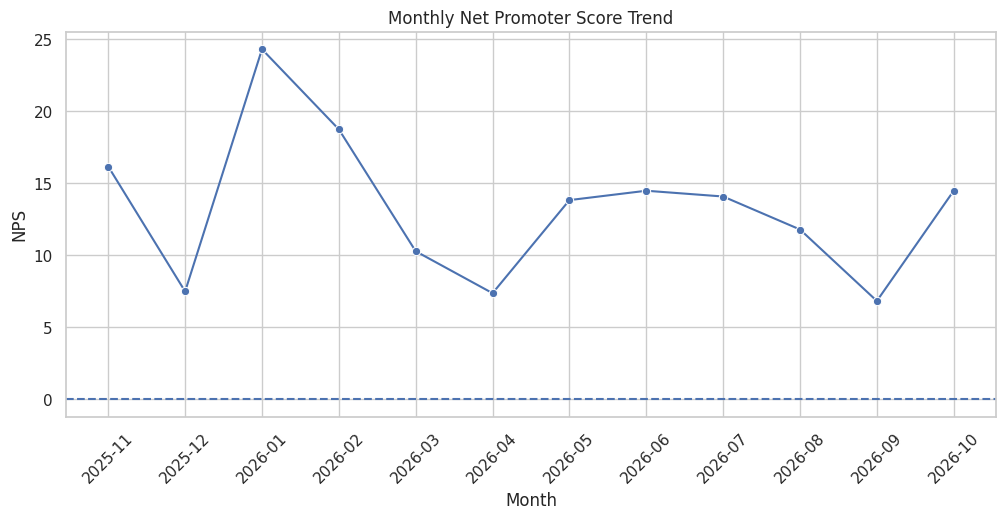

In [70]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_analysis.reset_index(),
    x='Month',
    y='nps',
    marker='o'
)

plt.axhline(y=0, linestyle='--')

plt.title('Monthly Net Promoter Score Trend')
plt.xlabel('Month')
plt.ylabel('NPS')
plt.xticks(rotation=45)
plt.show()

* Bulan dengan CSAT tertinggi dan terendah.
* Bulan dengan NPS tertinggi dan terendah.
* Apakah penurunan CSAT diikuti peningkatan unresolved rate?
* Apakah jumlah respons bulanan relatif stabil?
* Apakah ada perubahan besar yang perlu diinvestigasi?

## Correlation Analysis

In [71]:
df['FCR_Numeric'] = (
    df['First_Contact_Resolution'].astype(int)
)

In [72]:
correlation_data = df[
    [
        'CSAT_Score',
        'NPS_Score',
        'Response_Time_Min',
        'FCR_Numeric'
    ]
]

In [73]:
correlation_matrix = correlation_data.corr(
    method='pearson'
).round(3)

correlation_matrix

,CSAT_Score,NPS_Score,Response_Time_Min,FCR_Numeric
CSAT_Score,1.000,0.753,-0.090,0.365
NPS_Score,0.753,1.000,-0.039,0.382
Response_Time_Min,-0.090,-0.039,1.000,-0.015
FCR_Numeric,0.365,0.382,-0.015,1.000


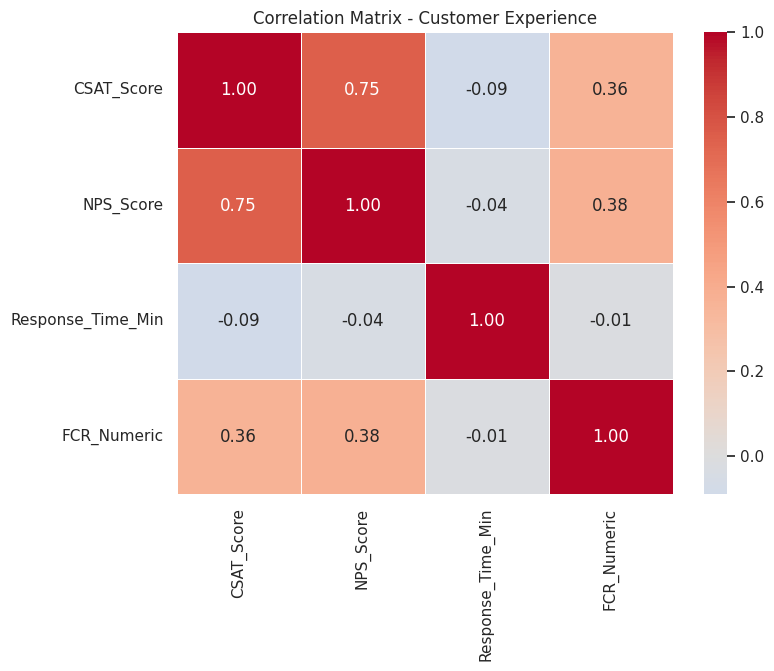

In [74]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix - Customer Experience')
plt.show()

Relationship	Pertanyaan bisnis
Response Time vs CSAT	Apakah respons lebih lama berkaitan dengan kepuasan lebih rendah?
Response Time vs NPS	Apakah respons lebih lama berkaitan dengan NPS lebih rendah?
CSAT vs NPS	Apakah pelanggan yang puas juga cenderung menjadi Promoters?
FCR vs CSAT	Apakah penyelesaian pada kontak pertama berkaitan dengan CSAT lebih tinggi?
Response Time vs FCR	Apakah respons awal yang cepat berkaitan dengan FCR lebih tinggi?

Saran penting: jangan hanya menyimpan grafik. Di bawah setiap grafik, tambahkan Markdown berisi:
1. What happened? — Apa yang terlihat?
2. Why does it matter? — Mengapa penting bagi bisnis?
3. What should be investigated? — Apa yang perlu diperiksa lebih lanjut?